In [1]:
from petrel_client.client import Client
c = Client()



2024-12-30 15:03:39,323 DEB [MainProcess] [MainThread] - init log, SDK version v2.2.2-10086 [P:238609 T:140164753086272 F:log.py:88]
2024-12-30 15:03:39,324 DEB [MainProcess] [MainThread] - init MixedClient, conf_path /mnt/petrelfs/yanziang/petreloss.conf [P:238609 T:140164753086272 F:mixed_client.py:35]
2024-12-30 15:03:39,377 DEB [MainProcess] [MainThread] - init MC, server list path: /mnt/lustre/share/memcached_client/server_list.conf, client config path: /mnt/lustre/share/memcached_client/client.conf [P:238609 T:140164753086272 F:mc.py:67]
2024-12-30 15:03:39,378 DEB [MainProcess] [MainThread] - create MC(id: 140164590053904) [P:238609 T:140164753086272 F:client_base.py:20]
2024-12-30 15:04:19,866 DEB [MainProcess] [MainThread] - create S3Client(pssd, id: 140164513764288) [P:238609 T:140164753086272 F:client_base.py:20]
2024-12-30 15:04:20,907 DEB [MainProcess] [MainThread] - create S3Client(pvideo, id: 140163975916480) [P:238609 T:140164753086272 F:client_base.py:20]
2024-12-30 15

In [2]:
b = c.list('sssdza:s3://LongVideoBench')
for i in b:
    print(i)
    # break
# pnorm2:s3://finevideo/all_clips/7My3N8HVUfA_scene_1.mp4
# d = c.get('pnorm2:s3://finevideo/videos/7My3N8HVUfA_scene_1.mp4')
# d is None

.huggingface/
subtitles/
videos/
.gitattributes
README.md
lvb_test_wo_gt.json
lvb_val.json
test-00000-of-00001.parquet
validation-00000-of-00001.parquet


In [26]:
kinds = []
for dd in c.list('pnorm2:s3://lasot/'):
    if dd not in ['zips/', 'syncRecord.txt', 'videos/']:
        kinds.append(dd)

# print(kinds[0])
paths = []
for dd in kinds:
    path = 'pnorm2:s3://lasot/' + dd + dd  
    for tt in c.list(path):
        if '-' in tt:
          paths.append(path + tt)

for dd in c.list(paths[0]):
    print(dd)

print(len(paths))

img/
full_occlusion.txt
groundtruth.txt
nlp.txt
out_of_view.txt
black bird standing on a handrail
1320


In [94]:
print(paths[0])
import numpy as np
import cv2
img_bytes = c.get(paths[0] + 'img/00000001.jpg')
img_np = np.frombuffer(img_bytes, np.uint8)
img = cv2.imdecode(img_np, cv2.IMREAD_COLOR)
cv2.cvtColor(img, cv2.COLOR_BGR2RGB, img)
print(img.shape)
h, w = img.shape[0], img.shape[1]

nlp = c.get(paths[0] + 'nlp.txt').decode()

box = c.get(paths[0] + 'groundtruth.txt').decode()
input_boxes = [int(n) for n in box.split('\n')[0].split(',')]
input_boxes[2], input_boxes[3] = input_boxes[0] + input_boxes[2], input_boxes[1] + input_boxes[3]
print(input_boxes)
input_boxes = [input_boxes[0] / w, input_boxes[1] / h,input_boxes[2] / w , input_boxes[3] / h]

print(input_boxes)

pnorm2:s3://lasot/bird/bird/bird-1/
(360, 480, 3)
[207, 120, 228, 166]
[0.43125, 0.3333333333333333, 0.475, 0.46111111111111114]


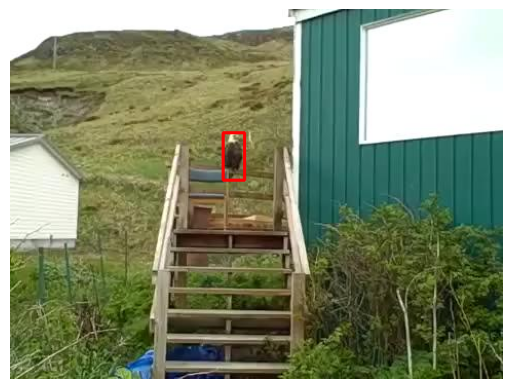

In [96]:
import cv2
import matplotlib.pyplot as plt
# img_bytes = c.get(paths[0] + 'img/00000001.jpg')
# img_np = np.frombuffer(img_bytes, np.uint8)
# img = cv2.imdecode(img_np, cv2.IMREAD_COLOR)
# cv2.cvtColor(img, cv2.COLOR_BGR2RGB, img)
plt.imshow(img)

box_coords = [0.43125, 0.3333333333333333, 0.475, 0.46111111111111114]
x_min, y_min, x_max, y_max = box_coords

height, width, _ = img.shape

x_min_abs = int(x_min * width)
y_min_abs = int(y_min * height)
x_max_abs = int(x_max * width)
y_max_abs = int(y_max * height)

# 在图像上绘制矩形框
cv2.rectangle(img, (x_min_abs, y_min_abs), (x_max_abs, y_max_abs), (255, 0, 0), 2)
plt.axis('off')  # 不显示坐标轴
plt.show()

In [9]:
import jsonlines
data = []
with jsonlines.open('/mnt/petrelfs/yanziang/trackingllm/videoagent/predictions27.jsonl', 'r') as f:
    for dd in f:
        data.append(dd)
print(data[0])

{'video': 'pnorm2:s3://lasot/videos/bird-1.mp4', 'input_boxes': [0.431640625, 0.333984375, 0.474609375, 0.4609375], 'pred': [[0.36328125, 0.330078125, 0.47265625, 0.466796875], [0.43359375, 0.330078125, 0.56640625, 0.455078125], [0.43359375, 0.333984375, 0.55078125, 0.453125], [0.43359375, 0.333984375, 0.5546875, 0.455078125], [0.43359375, 0.333984375, 0.5546875, 0.455078125], [0.43359375, 0.3359375, 0.5546875, 0.458984375], [0.43359375, 0.3359375, 0.5546875, 0.453125], [0.43359375, 0.333984375, 0.5546875, 0.453125], [0.435546875, 0.333984375, 0.5546875, 0.455078125], [0.435546875, 0.333984375, 0.546875, 0.455078125], [0.4375, 0.333984375, 0.5, 0.455078125], [0.435546875, 0.333984375, 0.5546875, 0.455078125], [0.435546875, 0.328125, 0.55859375, 0.453125], [0.435546875, 0.32421875, 0.55859375, 0.447265625], [0.435546875, 0.3203125, 0.546875, 0.44140625], [0.435546875, 0.3203125, 0.498046875, 0.439453125], [0.435546875, 0.31640625, 0.5546875, 0.439453125]]}


In [55]:
import numpy as np
from sklearn.metrics import precision_recall_curve, auc

def calculate_iou(box1, box2):
    x1, y1, w1, h1 = box1
    x2, y2, w2, h2 = box2
    
    xi1 = max(x1, x2)
    yi1 = max(y1, y2)
    xi2 = min(x1 + w1, x2 + w2)
    yi2 = min(y1 + h1, y2 + h2)
    
    inter_area = max(0, xi2 - xi1) * max(0, yi2 - yi1)
    box1_area = w1 * h1
    box2_area = w2 * h2
    union_area = box1_area + box2_area - inter_area
    
    iou = inter_area / union_area
    return iou

def calculate_metrics(gt_boxes, pred_boxes, iou_threshold=0.5):
    y_true = []
    y_scores = []
    
    for gt_box in gt_boxes:
        best_iou = 0
        best_score = 0
        for pred_box in pred_boxes:
            iou = calculate_iou(gt_box, pred_box)
            if iou > best_iou:
                best_iou = iou
                best_score = 1  # 假设预测框的第五个元素是置信度分数
        y_true.append(1 if best_iou >= iou_threshold else 0)
        y_scores.append(best_score)
    
    precision, recall, _ = precision_recall_curve(y_true, y_scores)
    auc_score = auc(recall, precision)
    
    normalized_precision = np.mean(precision)
    precision_at_threshold = precision[np.argmax(recall >= iou_threshold)]
    
    return auc_score, normalized_precision, precision_at_threshold

# 示例输入
gt_boxes = [[50, 50, 100, 100], [150, 150, 100, 100]]
pred_boxes = [[55, 55, 90, 90], [145, 145, 110, 110]]

# 计算指标
auc_score, normalized_precision, precision_at_threshold = calculate_metrics(gt_boxes, pred_boxes)
print(f"AUC: {auc_score}")
print(f"Normalized Precision: {normalized_precision}")
print(f"Precision: {precision_at_threshold}")

AUC: 1.0
Normalized Precision: 1.0
Precision: 1.0


In [57]:
auc1s, normalized_precisions, precisions = [], [], []
for dd in data:
    gt_file = 'pnorm2:s3://lasot/' + dd['video'].split('/')[-1].split('-')[0] + '/' + dd['video'].split('/')[-1].split('-')[0] + '/' + dd['video'].split('/')[-1].split('.')[0] + '/groundtruth.txt'
    gt = c.get(gt_file).decode()
    gt = gt.split('\n')
    gt = [ tt.split(',') for tt in gt]
    gt_f = []
    for tt in gt:
        if tt == ['']:
            gt_f.append([-1,-1,-1,-1])
        else:
            gt_f.append([int(f) for f in tt])

    raw_size = [(gt_f[0][2] + gt_f[0][0]) / dd['input_boxes'][2], (gt_f[0][1] + gt_f[0][3]) / dd['input_boxes'][3]]
    pred = []
    for tt in dd['pred']:
        pred.append([tt[0] * raw_size[0], tt[1] * raw_size[1], tt[2] * raw_size[0], tt[3] * raw_size[1]])
    gt_f2 = []
    for tt in gt_f:
        gt_f2.append([tt[0], tt[1], tt[0] + tt[2], tt[1] + tt[3]])
    auc1, normalized_precision, precision= calculate_metrics(gt_f2[:16], pred[:16])
    # print(auc, normalized_precision, precision)
    auc1s.append(auc1)
    normalized_precisions.append(normalized_precision)
    precisions.append(precision)
    # print(auc1)
    # break
auc1s = np.mean(np.array(auc1s))
print(auc1s)

/mnt/petrelfs/yanziang/.conda/envs/mllm/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/mnt/petrelfs/yanziang/.conda/envs/mllm/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/mnt/petrelfs/yanziang/.conda/envs/mllm/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/mnt/petrelfs/yanziang/.conda/envs/mllm/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/mnt/petrelfs/yanziang/.conda/envs/mllm/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set

KeyboardInterrupt: 

In [11]:
gt_file

'pnorm2:s3://lasot/tank/tank/tank-19/groundtruth.txt'

In [61]:
# len(auc1s)
# auc1s = np.mean(np.array(auc1s))
auc1s

0.9549142643507431

In [62]:
normalized_precisions = np.mean(np.array(normalized_precisions))
normalized_precisions

0.9547167027056157

In [1]:
tt = c.list('pnorm2:s3://lasot/bird/bird/bird-1/')
# tt = c.list('pnorm2:s3://mevis/train/JPEGImages')
for dd in tt:
    print(dd)

NameError: name 'c' is not defined

AUC: 0.54
Normalized Precision: 0.5
Precision: 1.0
